In [2]:
import pandas as pd
import yfinance as yf
import numpy as np  
import matplotlib.pyplot as plt
from scipy.stats import norm
import datetime as dt

In [3]:
years = 15
end_date = dt.datetime.now()
start_date = end_date - dt.timedelta(days = years*365)

In [4]:
#S&P500, Bonds, Gold, Nasdaq, Vanguard Total Stock Market Index
tickers  = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']
adj_close_df = pd.DataFrame()

for ticker in tickers:
    data = yf.download(ticker, start=start_date, end=end_date, auto_adjust=False)
    adj_close_df[ticker] = data['Adj Close']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [5]:
#calculating daily log returns
log_returns = np.log(adj_close_df/adj_close_df.shift(1)).dropna()

In [6]:
portfolio_value= 1000000
weights =np.array([1/len(tickers)]*len(tickers))
weights

array([0.2, 0.2, 0.2, 0.2, 0.2])

In [11]:
historical_returns = (log_returns*weights).sum(axis=1)

Find the X day historical returns


In [12]:
days = 5
range_returns = historical_returns.rolling(window=days).sum().dropna()
print(range_returns)

Date
2010-07-29   -0.001191
2010-07-30   -0.001558
2010-08-02    0.005660
2010-08-03    0.008034
2010-08-04    0.017300
                ...   
2025-07-14    0.004496
2025-07-15    0.003549
2025-07-16    0.001012
2025-07-17    0.003481
2025-07-18    0.004582
Length: 3766, dtype: float64


In [14]:
#setting confidence interval and calculating VaR
confidence_interval = 0.95
var = -np.percentile(range_returns, 100-(confidence_interval*100)) * portfolio_value
print(f"Value at Risk (VaR) at {confidence_interval*100}% confidence level: ${var:,.2f}")

Value at Risk (VaR) at 95.0% confidence level: $23,421.18


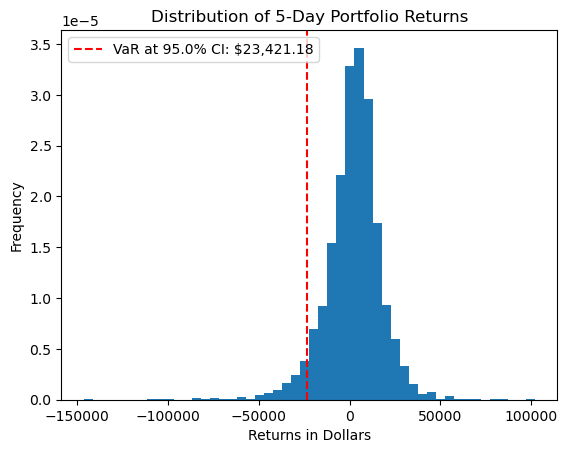

In [16]:
#plotting the historical returns
return_window = days
return_range_dollars = range_returns * portfolio_value

plt.hist(return_range_dollars.dropna(), bins=50, density=True)
plt.title(f'Distribution of {return_window}-Day Portfolio Returns')
plt.xlabel(f'Returns in Dollars')
plt.ylabel('Frequency')
plt.axvline(x=-var, color='red', linestyle= '--', label=f'VaR at {confidence_interval*100}% CI: ${var:,.2f}')
plt.legend()
plt.show()